In [1]:
!pip install mlflow
import mlflow



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
mlflow.set_experiment("Ecommerce_Customer_Segmentation")

2026/10/19 17:33:31 INFO mlflow.tracking.fluent: Experiment with name 'Ecommerce_Customer_Segmentation' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:///e:/ecomerce_project/mlruns/5', creation_time=1792411411347, effective_trace_archival_retention=None, experiment_id='5', last_update_time=1792411411347, lifecycle_stage='active', name='Ecommerce_Customer_Segmentation', tags={}, trace_location=None, workspace='default'>

Injestion

In [3]:
from google.colab import files

uploaded = files.upload()
import pandas as pd


ModuleNotFoundError: No module named 'google.colab'

In [ ]:
df = pd.read_csv("ecommerce_customers.csv")

print("Shape:", df.shape)
display(df.head())
df.info()
print("Shape:", df.shape)
display(df.head())
print(df.info())

Shape: (100, 40)


,customer_id,age,gender,annual_income,spending_score,purchase_frequency,avg_order_value,total_purchases,browsing_time_minutes,product_category_preference,...,cross_category_purchases,repeat_purchase_rate,avg_session_duration,pages_per_session,geographic_region,preferred_shipping,support_interactions,product_reviews_count,social_shares,coupon_redemptions
0,1,58,Male,16639,93,16,92.35,16,157,Clothing,...,3,0.76,1008,3,South,Same Day,1,8,4,1
1,2,66,Female,21698,72,18,87.90,18,184,Home & Garden,...,1,0.93,1055,6,North,Same Day,1,14,5,2
2,3,28,Female,38283,76,16,106.05,16,227,Clothing,...,3,0.84,397,13,West,Same Day,2,14,1,2
3,4,26,Male,32219,93,18,111.93,18,191,Beauty,...,1,0.76,876,14,North,Overnight,2,10,0,2
4,5,45,Male,44735,70,16,114.16,16,237,Home & Garden,...,1,0.85,267,14,West,Standard,2,4,4,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   customer_id                  100 non-null    int64  
 1   age                          100 non-null    int64  
 2   gender                       100 non-null    object 
 3   annual_income                100 non-null    int64  
 4   spending_score               100 non-null    int64  
 5   purchase_frequency           100 non-null    int64  
 6   avg_order_value              100 non-null    float64
 7   total_purchases              100 non-null    int64  
 8   browsing_time_minutes        100 non-null    int64  
 9   product_category_preference  100 non-null    object 
 10  device_type                  100 non-null    object 
 11  last_purchase_days           100 non-null    int64  
 12  segment                      100 non-null    object 
 13  customer_lifetime_val

,customer_id,age,gender,annual_income,spending_score,purchase_frequency,avg_order_value,total_purchases,browsing_time_minutes,product_category_preference,...,cross_category_purchases,repeat_purchase_rate,avg_session_duration,pages_per_session,geographic_region,preferred_shipping,support_interactions,product_reviews_count,social_shares,coupon_redemptions
0,1,58,Male,16639,93,16,92.35,16,157,Clothing,...,3,0.76,1008,3,South,Same Day,1,8,4,1
1,2,66,Female,21698,72,18,87.90,18,184,Home & Garden,...,1,0.93,1055,6,North,Same Day,1,14,5,2
2,3,28,Female,38283,76,16,106.05,16,227,Clothing,...,3,0.84,397,13,West,Same Day,2,14,1,2
3,4,26,Male,32219,93,18,111.93,18,191,Beauty,...,1,0.76,876,14,North,Overnight,2,10,0,2
4,5,45,Male,44735,70,16,114.16,16,237,Home & Garden,...,1,0.85,267,14,West,Standard,2,4,4,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   customer_id                  100 non-null    int64  
 1   age                          100 non-null    int64  
 2   gender                       100 non-null    object 
 3   annual_income                100 non-null    int64  
 4   spending_score               100 non-null    int64  
 5   purchase_frequency           100 non-null    int64  
 6   avg_order_value              100 non-null    float64
 7   total_purchases              100 non-null    int64  
 8   browsing_time_minutes        100 non-null    int64  
 9   product_category_preference  100 non-null    object 
 10  device_type                  100 non-null    object 
 11  last_purchase_days           100 non-null    int64  
 12  segment                      100 non-null    object 
 13  customer_lifetime_val

In [ ]:
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

customer_id                    0
age                            0
gender                         0
annual_income                  0
spending_score                 0
purchase_frequency             0
avg_order_value                0
total_purchases                0
browsing_time_minutes          0
product_category_preference    0
device_type                    0
last_purchase_days             0
segment                        0
customer_lifetime_value        0
return_rate                    0
payment_method                 0
newsletter_subscribed          0
social_media_engagement        0
avg_review_rating              0
cart_abandonment_rate          0
discount_usage_pct             0
referral_source                0
customer_satisfaction_score    0
preferred_shopping_hour        0
mobile_app_user                0
wishlist_items                 0
customer_since_months          0
loyalty_tier                   0
email_open_rate                0
click_through_rate             0
cross_cate

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,100.0,NaN,NaN,NaN,50.5,29.011492,1.0,25.75,50.5,75.25,100.0
age,100.0,NaN,NaN,NaN,41.73,15.618466,18.0,28.0,39.5,54.25,70.0
gender,100,2,Male,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income,100.0,NaN,NaN,NaN,31490.33,10169.220141,15912.0,22517.25,30784.5,40469.25,49962.0
spending_score,100.0,NaN,NaN,NaN,50.5,31.976159,3.0,17.75,43.5,83.25,100.0
purchase_frequency,100.0,NaN,NaN,NaN,10.04,5.697634,1.0,5.0,10.0,15.0,20.0
avg_order_value,100.0,NaN,NaN,NaN,183.6468,98.881658,85.42,105.1625,160.745,222.7875,447.96
total_purchases,100.0,NaN,NaN,NaN,10.04,5.697634,1.0,5.0,10.0,15.0,20.0
browsing_time_minutes,100.0,NaN,NaN,NaN,107.41,74.109133,5.0,42.0,87.0,177.25,240.0
product_category_preference,100,6,Beauty,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Numerical customer behavior features
numeric_features = [
    "age",
    "annual_income",
    "spending_score",
    "purchase_frequency",
    "avg_order_value",
    "total_purchases",
    "browsing_time_minutes",
    "last_purchase_days",
    "return_rate",
    "social_media_engagement",
    "avg_review_rating",
    "cart_abandonment_rate",
    "discount_usage_pct",
    "customer_satisfaction_score",
    "preferred_shopping_hour",
    "wishlist_items",
    "customer_since_months",
    "email_open_rate",
    "click_through_rate",
    "cross_category_purchases",
    "repeat_purchase_rate",
    "avg_session_duration",
    "pages_per_session",
    "support_interactions",
    "product_reviews_count",
    "social_shares",
    "coupon_redemptions",
]

# Categorical customer behavior features
categorical_features = [
    "gender",
    "product_category_preference",
    "device_type",
    "payment_method",
    "newsletter_subscribed",
    "mobile_app_user",
    "loyalty_tier",
    "referral_source",
    "geographic_region",
    "preferred_shipping",
]

feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()

print("Rows:", X.shape[0])
print("Selected features:", X.shape[1])
print("Missing values:", X.isna().sum().sum())

Rows: 100
Selected features: 37
Missing values: 0


In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

encoded_array = encoder.fit_transform(
    X[categorical_features]
)

encoded_columns = encoder.get_feature_names_out(
    categorical_features
)

X_encoded = pd.DataFrame(
    encoded_array,
    columns=encoded_columns,
    index=X.index
)

print("Encoded shape:", X_encoded.shape)
display(X_encoded.head())

Encoded shape: (100, 42)


,gender_Female,gender_Male,product_category_preference_Beauty,product_category_preference_Books,product_category_preference_Clothing,product_category_preference_Electronics,product_category_preference_Home & Garden,product_category_preference_Sports,device_type_Desktop,device_type_Mobile,...,referral_source_Social Media,geographic_region_Central,geographic_region_East,geographic_region_North,geographic_region_South,geographic_region_West,preferred_shipping_Express,preferred_shipping_Overnight,preferred_shipping_Same Day,preferred_shipping_Standard
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(
    X[numeric_features]
)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=numeric_features,
    index=X.index
)

print("Scaled numerical shape:", X_scaled.shape)
display(X_scaled.head())

Scaled numerical shape: (100, 27)


,age,annual_income,spending_score,purchase_frequency,avg_order_value,total_purchases,browsing_time_minutes,last_purchase_days,return_rate,social_media_engagement,...,email_open_rate,click_through_rate,cross_category_purchases,repeat_purchase_rate,avg_session_duration,pages_per_session,support_interactions,product_reviews_count,social_shares,coupon_redemptions
0,1.046964,-1.467777,1.335811,1.051318,-0.927945,1.051318,0.672519,-0.778902,-1.153455,1.675949,...,0.708660,0.625336,1.493767,0.556971,1.126737,-1.499448,-0.466832,0.757506,-0.012521,-0.746083
1,1.561758,-0.967789,0.675763,1.404109,-0.973175,1.404109,1.038682,-0.818723,-0.983028,-0.592253,...,-1.055875,-1.077312,-0.458870,1.342740,1.280159,-0.697604,-0.466832,2.155978,0.237891,-0.288363
2,-0.883516,0.671329,0.801487,1.051318,-0.788698,1.051318,1.621831,-0.778902,-1.187541,0.163815,...,0.253296,-0.148595,1.493767,0.926745,-0.867748,1.173365,0.338051,2.155978,-0.763754,-0.288363
3,-1.012215,0.072015,1.335811,1.404109,-0.728933,1.404109,1.133613,-0.898365,-1.034156,-0.556250,...,-1.055875,-0.922525,-0.458870,0.556971,0.695850,1.440646,0.338051,1.223663,-1.014165,-0.288363
4,0.210422,1.308989,0.612902,1.051318,-0.706267,1.051318,1.757447,-0.938187,-0.744429,1.855965,...,0.367137,-0.148595,-0.458870,0.972966,-1.292106,1.440646,0.338051,-0.174809,-0.012521,0.169356


In [ ]:
X_final = pd.concat(
    [X_scaled, X_encoded],
    axis=1
)


display(X_final.head())

,age,annual_income,spending_score,purchase_frequency,avg_order_value,total_purchases,browsing_time_minutes,last_purchase_days,return_rate,social_media_engagement,...,referral_source_Social Media,geographic_region_Central,geographic_region_East,geographic_region_North,geographic_region_South,geographic_region_West,preferred_shipping_Express,preferred_shipping_Overnight,preferred_shipping_Same Day,preferred_shipping_Standard
0,1.046964,-1.467777,1.335811,1.051318,-0.927945,1.051318,0.672519,-0.778902,-1.153455,1.675949,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.561758,-0.967789,0.675763,1.404109,-0.973175,1.404109,1.038682,-0.818723,-0.983028,-0.592253,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.883516,0.671329,0.801487,1.051318,-0.788698,1.051318,1.621831,-0.778902,-1.187541,0.163815,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,-1.012215,0.072015,1.335811,1.404109,-0.728933,1.404109,1.133613,-0.898365,-1.034156,-0.556250,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.210422,1.308989,0.612902,1.051318,-0.706267,1.051318,1.757447,-0.938187,-0.744429,1.855965,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [ ]:
import time
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

results = []
inertias = []

for k in range(2, 9):
  with mlflow.start_run(run_name=f"KMeans_k{k}"):
    start_time=time.time()
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    clusters = model.fit_predict(X_final)
    training_time=time.time()-start_time
    mlflow.log_param("algorithm", "KMeans")
    mlflow.log_param("n_cluters",k)
    mlflow.log_param("n_init", 20)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("n_samples", X_final.shape[0])
    mlflow.log_param("n_features", X_final.shape[1])
    #metrics log
    mlflow.log_metric(
            "silhouette_score",
            silhouette_score(X_final, clusters)
        )

    mlflow.log_metric(
            "davies_bouldin_score",
            davies_bouldin_score(X_final, clusters)
        )

    mlflow.log_metric(
            "calinski_harabasz_score",
            calinski_harabasz_score(X_final, clusters)
        )
    inertias.append(model.inertia_)

    mlflow.log_metric("inertia", model.inertia_)
    mlflow.log_metric("training_time_seconds", training_time)

    results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette Score": round(
            silhouette_score(X_final, clusters), 4
        ),
        "Davies-Bouldin Index": round(
            davies_bouldin_score(X_final, clusters), 4
        ),
        "Calinski-Harabasz Score": round(
            calinski_harabasz_score(X_final, clusters), 2
        )
    })

results_df = pd.DataFrame(results)
display(results_df)


,K,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,2414.09,0.2387,1.5233,39.07
1,3,2120.54,0.1631,2.0028,28.73
2,4,2001.82,0.1342,2.2453,21.97
3,5,1908.61,0.1200,2.3408,18.27
4,6,1816.53,0.1096,2.3609,16.14
5,7,1764.21,0.0937,2.4326,14.17
6,8,1727.86,0.0719,2.5281,12.54


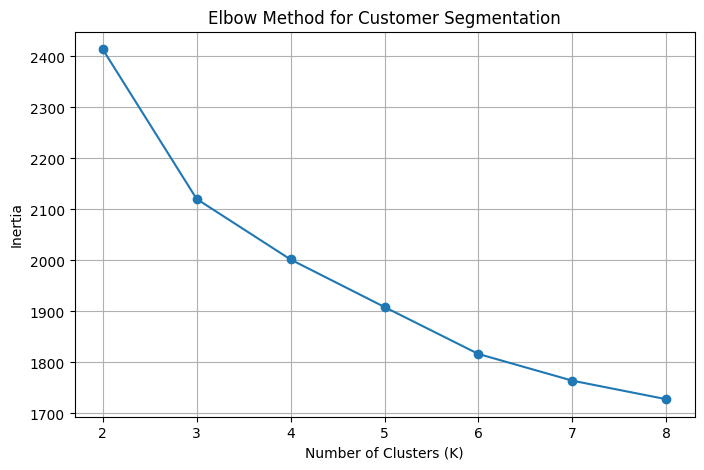

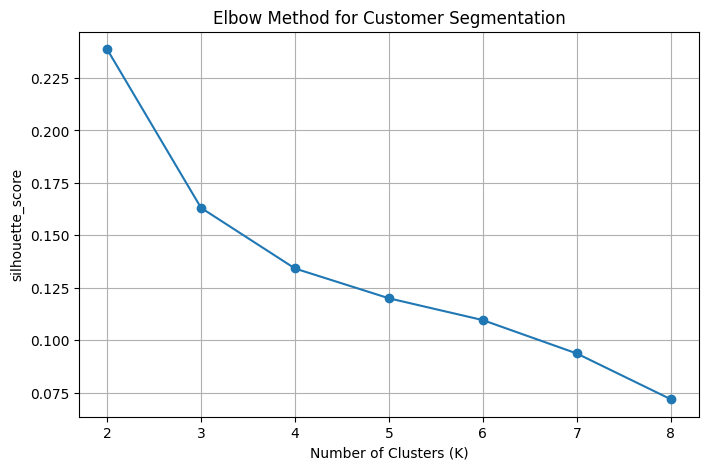

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(list(range(2,9)), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(list(range(2,9)))
plt.grid(True)
plt.show()
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(list(range(2,9)), results_df["Silhouette Score"], marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("silhouette_score")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(list(range(2,9)))
plt.grid(True)
plt.show()

In [ ]:

final_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

df["predicted_cluster"] = final_model.fit_predict(X_final)

print(df["predicted_cluster"].value_counts().sort_index())

predicted_cluster
0    30
1    30
2    40
Name: count, dtype: int64


In [ ]:
cluster_profile = df.groupby("predicted_cluster")[
    [
        "age",
        "annual_income",
        "spending_score",
        "purchase_frequency",
        "avg_order_value",
        "last_purchase_days"
    ]
].mean().round(2)

display(cluster_profile)

,age,annual_income,spending_score,purchase_frequency,avg_order_value,last_purchase_days
predicted_cluster,,,,,,
0,40.33,32151.83,40.20,9.13,166.79,21.07
1,42.83,32117.43,13.13,3.07,310.99,59.60
2,41.95,30523.88,86.25,15.95,100.79,3.40


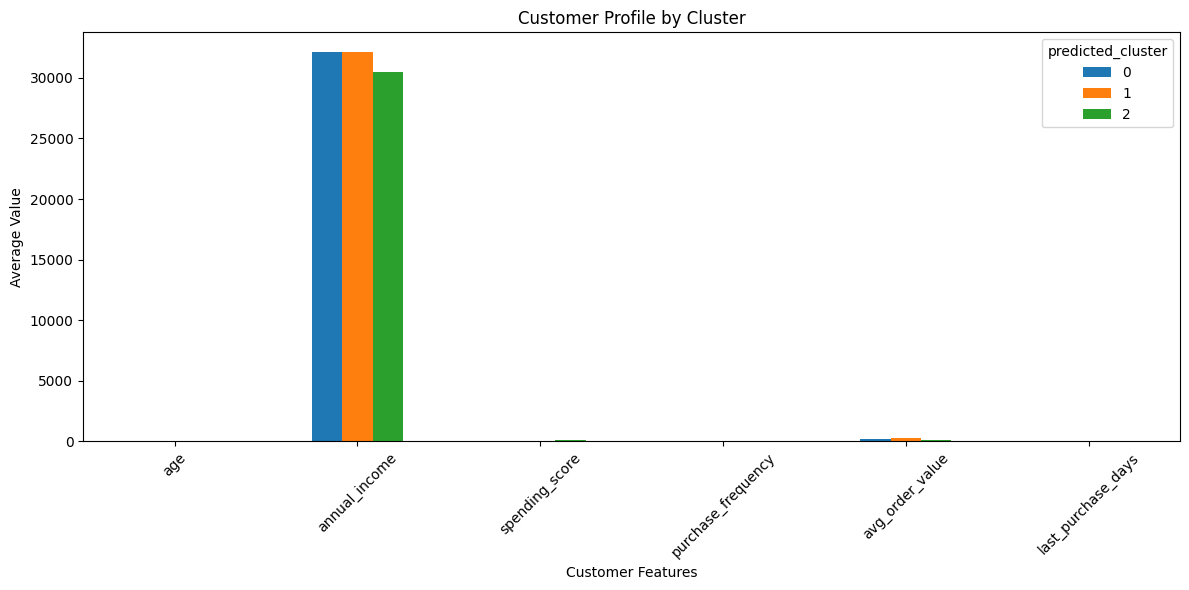

In [ ]:
cluster_profile.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Customer Profile by Cluster")
plt.xlabel("Customer Features")
plt.ylabel("Average Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

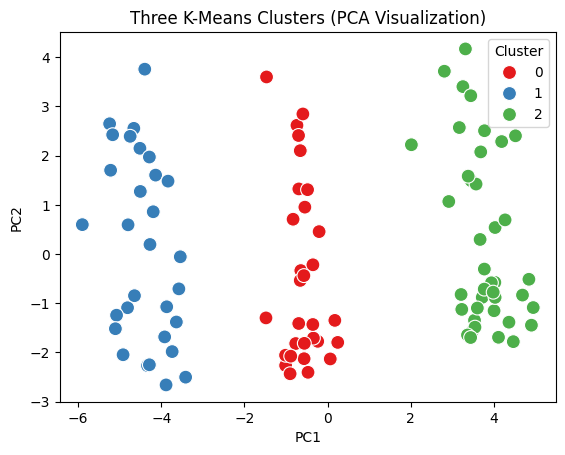

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_final)

plot_df = pd.DataFrame({
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "Cluster": df["predicted_cluster"].values
})

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("Three K-Means Clusters (PCA Visualization)")
plt.show()

In [ ]:

customer_index = 1
original_customer = df.iloc[[customer_index]]

customer = X_final.iloc[[customer_index]]

prediction = final_model.predict(customer)

display(original_customer)
print("Customer belongs to Cluster:", prediction[0])

,customer_id,age,gender,annual_income,spending_score,purchase_frequency,avg_order_value,total_purchases,browsing_time_minutes,product_category_preference,...,repeat_purchase_rate,avg_session_duration,pages_per_session,geographic_region,preferred_shipping,support_interactions,product_reviews_count,social_shares,coupon_redemptions,predicted_cluster
1,2,66,Female,21698,72,18,87.9,18,184,Home & Garden,...,0.93,1055,6,North,Same Day,1,14,5,2,2


Customer belongs to Cluster: 2


In [ ]:
!mlflow ui --host 0.0.0.0 --port 5000

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/18 19:24:59 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/18 19:24:59 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/18 19:25:00 INFO:     Uvicorn running on http://0.0.0.0:5000 (Press CTRL+C to quit)
2026/10/18 19:25:00 INFO:     Started parent process [17135]
/usr/local/lib/python3.13/dist-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi import WSGIResponder, build

In [ ]:
import pandas as pd
import numpy as np

customer = pd.DataFrame([{
    "age": 22,
    "annual_income": 35000,
    "spending_score": 80,
    "purchase_frequency": 12,
    "avg_order_value": 1500,
    "total_purchases": 25,
    "browsing_time_minutes": 40,
    "last_purchase_days": 10,
    "return_rate": 0.05,
    "social_media_engagement": 60,
    "avg_review_rating": 4.5,
    "cart_abandonment_rate": 0.15,
    "discount_usage_pct": 20,
    "customer_satisfaction_score": 8,
    "preferred_shopping_hour": 18,
    "wishlist_items": 5,
    "customer_since_months": 12,
    "email_open_rate": 0.6,
    "click_through_rate": 0.2,
    "cross_category_purchases": 4,
    "repeat_purchase_rate": 0.7,
    "avg_session_duration": 12,
    "pages_per_session": 8,
    "support_interactions": 1,
    "product_reviews_count": 5,
    "social_shares": 3,
    "coupon_redemptions": 4,
    "gender": "Male",
    "product_category_preference": "Electronics",
    "device_type": "Mobile",
    "payment_method": "Credit Card",
    "newsletter_subscribed": "Yes",
    "mobile_app_user": "Yes",
    "loyalty_tier": "Gold",
    "referral_source": "Social Media",
    "geographic_region": "North",
    "preferred_shipping": "Standard"
}])


numeric_cols = customer.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = customer.select_dtypes(
    include=["object", "category", "bool"]
).columns

X_numeric = scaler.transform(customer[numeric_cols])


X_categorical = encoder.transform(customer[categorical_cols])


X_customer = np.concatenate(
    [X_numeric, X_categorical], axis=1
)


cluster = int(final_model.predict(X_customer)[0])

print("Predicted Cluster:", cluster)

In [ ]:

marketing_strategies = {
    0: {
        "segment": "Loyal / High-Value Customers",
        "strategy": "VIP Loyalty Program",
        "offer": "Exclusive rewards or early access",
        "reason": "Encourage repeat purchases and retain valuable customers."
    },
    1: {
        "segment": "Occasional Customers",
        "strategy": "Purchase Frequency Campaign",
        "offer": "10% off the next order above a minimum spend",
        "reason": "Give customers an incentive to purchase again."
    },
    2: {
        "segment": "Potentially Inactive Customers",
        "strategy": "Win-Back Campaign",
        "offer": "A time-limited return-customer offer",
        "reason": "Encourage customers to return and make another purchase."
    }
}

result = marketing_strategies.get(cluster)

if result:
    print("🎯 PREDICTED CLUSTER:", cluster)
    print("👥 CUSTOMER SEGMENT:", result["segment"])
    print("📈 STRATEGY:", result["strategy"])
    print("🎁 RECOMMENDED OFFER:", result["offer"])
    print("💡 WHY:", result["reason"])
else:
    print("No marketing strategy configured for this cluster.")